In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pynamicalsys import Billiard

In [2]:
def plot_billiard(bl, u, ax=None, total_time=100):
    # The boundary and a piece of a trajectory.
    if ax is None:
        _, ax = plt.subplots()
    boundary = bl.boundary()
    traj_xy = bl.to_cartesian(bl.trajectory(u, total_time))
    ax.plot(traj_xy[:, 0], traj_xy[:, 1], lw=0.5)
    ax.plot(boundary[:, 0], boundary[:, 1], "k")
    ax.set_aspect("equal")


def plot_phase_space(bl, ics, xlim, ylim, total_time=20_000):
    _, ax = plt.subplots()
    for u in ics:
        traj = bl.trajectory(u, total_time)
        ax.plot(traj[:, 0], traj[:, 1], "o", ms=0.25, mew=0)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

# Available billiards

In [3]:
print(Billiard.available_billiards())
print(Billiard.available_solvers("oval"))

['oval', 'stadium', 'sinai', 'mushroom']
['md', 'exact', 'circle', 'polygon']


# Oval billiard

$R(\theta) = 1 + \epsilon\cos(p\theta)$, with parameters `[eps, p]`.

In [4]:
bl = Billiard("oval", parameters=[0.2, 2], solver="circle")
print(bl.info)

{'name': 'oval', 'description': 'Oval billiard, R(theta) = 1 + eps cos(p theta)', 'parameters': ['eps', 'p'], 'state': ['theta', 'alpha'], 'period': 6.283185307179586, 'available_solvers': ['md', 'exact', 'circle', 'polygon'], 'solver': 'circle', 'coordinates': 'angles', 'md_steps': 500}


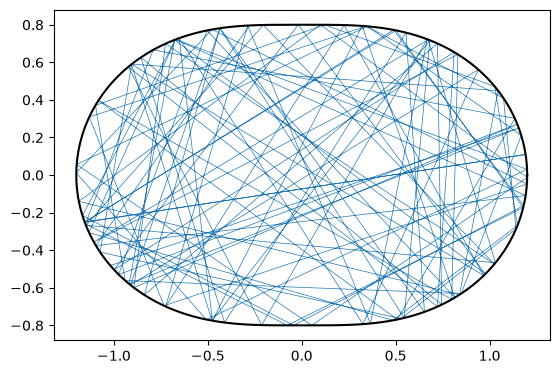

In [5]:
plot_billiard(bl, [2.0, 1.0])

(0.0, 3.141592653589793)

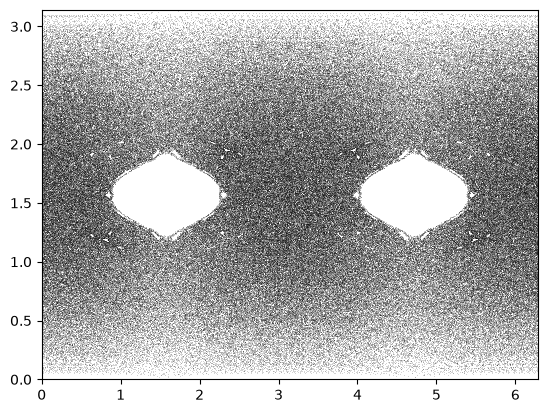

In [6]:
traj = bl.trajectory([2.0, 1.0], 500000)
plt.plot(traj[:,0], traj[:, 1], "ko", ms=0.25, mew=0)
plt.xlim(0, 2 * np.pi)
plt.ylim(0, np.pi)

## Birkhoff coordinates

The state is `(s, cos(alpha))`, and the map preserves area.

In [7]:
bl = Billiard("oval", parameters=[0.2, 2], solver="circle", coordinates="birkhoff")
traj = bl.trajectory([2.0, 0.5], 500000)
per = bl.perimeter()

(-1.0, 1.0)

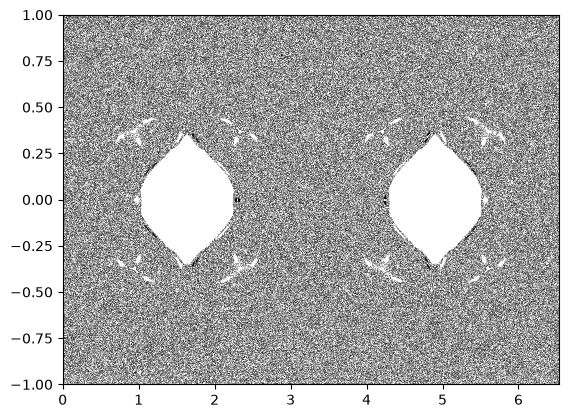

In [8]:
plt.plot(traj[:,0], traj[:, 1], "ko", ms=0.25, mew=0)
plt.xlim(0, per)
plt.ylim(-1, 1)

## Step size

A large step can skip the first collision.

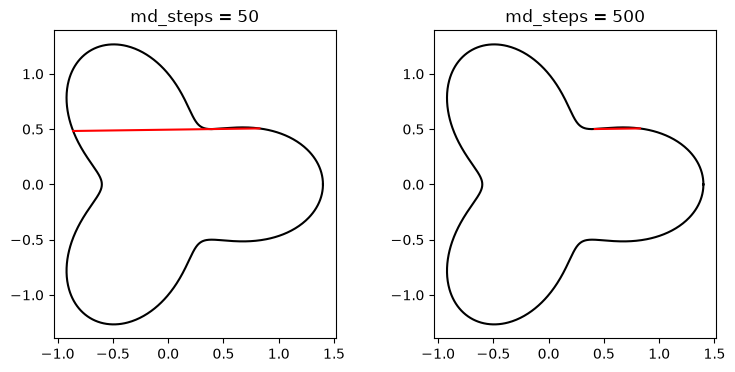

In [9]:
state = [0.55, 0.1442]
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for axis, md_steps in zip(ax, [50, 500]):
    bl = Billiard("oval", parameters=[0.4, 3], solver="md", md_steps=md_steps)
    plot_billiard(bl, state, axis, total_time=1)
    x0 = bl.to_cartesian(state)
    x1 = bl.to_cartesian(bl.trajectory(state, 1)[0])
    axis.plot([x0[0], x1[0]], [x0[1], x1[1]], "r")
    axis.set_title(f"md_steps = {md_steps}")

# Cardioid

The oval billiard with `eps = 1` and `p = 1`.

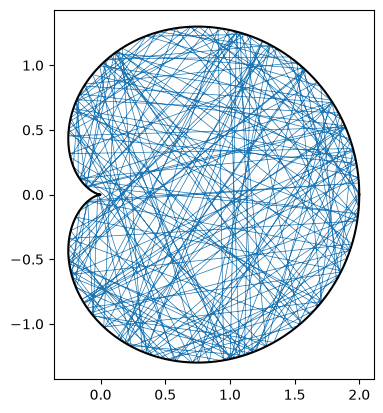

In [10]:
bl = Billiard("oval", parameters=[1, 1], solver="exact")
plot_billiard(bl, [1.0, 1.0], total_time=200)

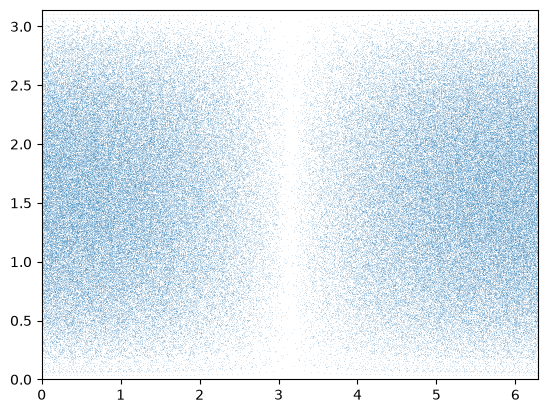

In [11]:
plot_phase_space(bl, [[1.0, 1.0]], (0, 2 * np.pi), (0, np.pi), 200_000)

# Stadium billiard

Parameters `[r, l]`. The position is the arc length.

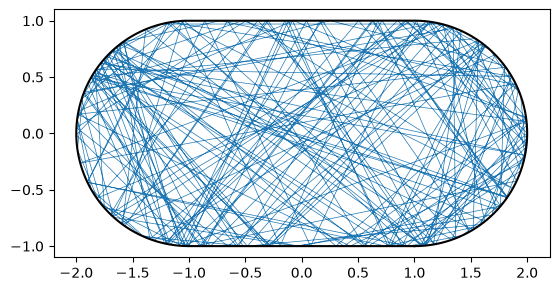

In [12]:
bl = Billiard("stadium", parameters=[1.0, 2.0], solver="exact")
plot_billiard(bl, [1.0, 1.0], total_time=200)

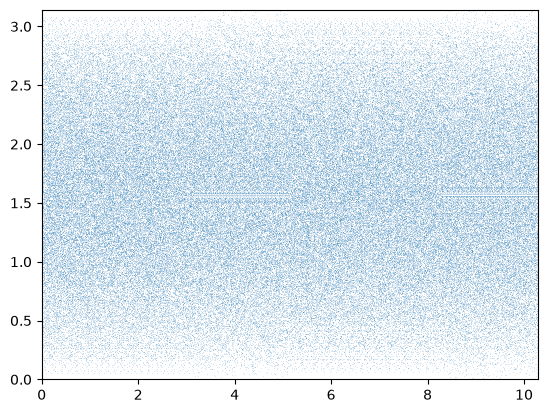

In [13]:
plot_phase_space(bl, [[1.0, 1.0]], (0, bl.perimeter()), (0, np.pi), 200_000)

# Sinai billiard

Parameters `[r, x_d, y_d]`: a disk in the unit square. The arc length runs along the walls, up to 4, and then around the disk.

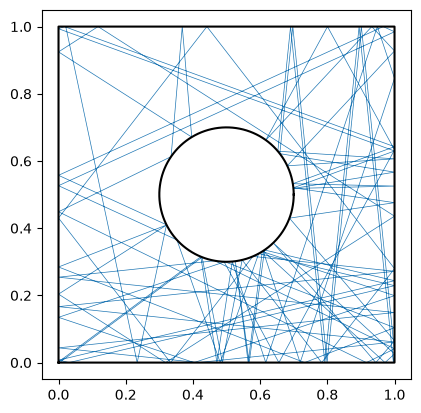

In [14]:
bl = Billiard("sinai", parameters=[0.2, 0.5, 0.5], solver="exact")
plot_billiard(bl, [0.3, 1.0], total_time=100)

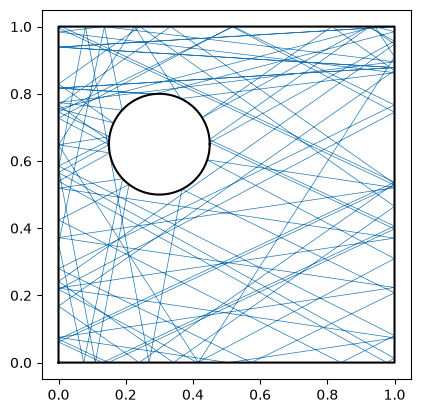

In [15]:
bl = Billiard("sinai", parameters=[0.15, 0.3, 0.65], solver="exact")  # Off center
plot_billiard(bl, [0.3, 1.0], total_time=100)

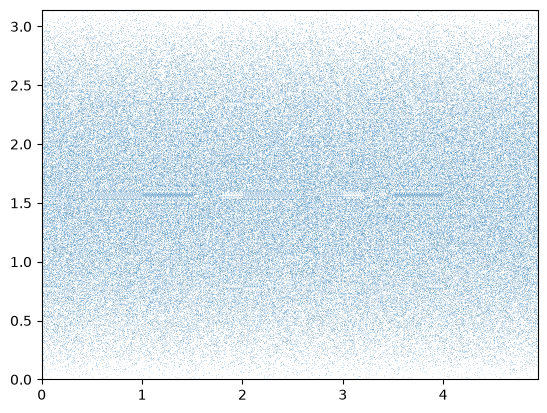

In [16]:
plot_phase_space(bl, [[0.3, 1.0]], (0, bl.perimeter()), (0, np.pi), 200_000)

# Mushroom billiard

Parameters `[R, w, h]`. Orbits with $R|\cos\alpha| > w/2$ on the hat never reach the stem.

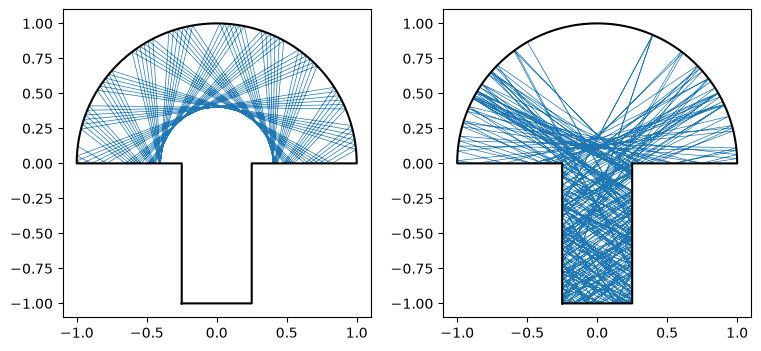

In [17]:
R, w, h = 1.0, 0.5, 1.0
bl = Billiard("mushroom", parameters=[R, w, h], solver="exact")
hat = w + h + (R - w / 2)  # Arc length at the start of the hat
regular = [hat + 0.7, np.arccos(0.4)]
chaotic = [hat + 0.7, np.arccos(0.1)]

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
plot_billiard(bl, regular, ax[0], total_time=100)
plot_billiard(bl, chaotic, ax[1], total_time=300)

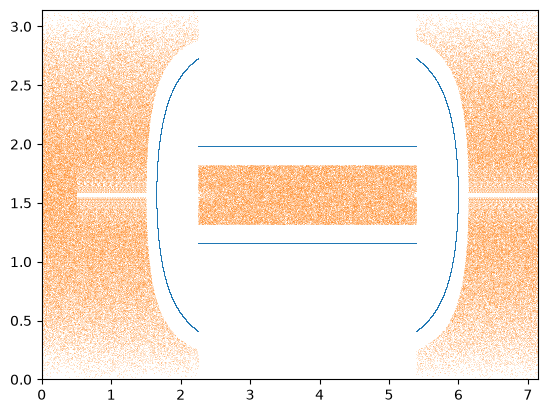

In [18]:
plot_phase_space(bl, [regular, chaotic], (0, bl.perimeter()), (0, np.pi), 200_000)

# Choosing a solver

Boundaries made of lines and arcs have an exact solver, which cannot miss a collision.

['md', 'exact']


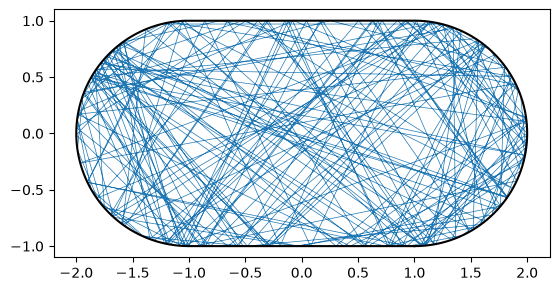

In [19]:
print(Billiard.available_solvers("stadium"))

bl = Billiard("stadium", parameters=[1.0, 2.0], solver="exact")
plot_billiard(bl, [1.0, 1.0], total_time=200)

In [20]:
md = Billiard("mushroom", parameters=[1.0, 0.5, 1.0], solver="md")
exact = Billiard("mushroom", parameters=[1.0, 0.5, 1.0], solver="exact")

%timeit md.trajectory([3.0, 1.0], 10_000)
%timeit exact.trajectory([3.0, 1.0], 10_000)

6.95 ms ± 114 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


3.65 ms ± 24.6 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


A trajectory that crosses the underside of the hat just outside the stem: molecular dynamics steps over the collision.

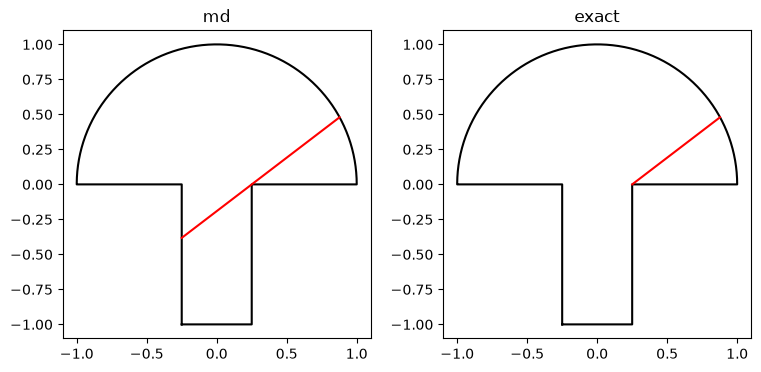

In [21]:
R, w, h = 1.0, 0.5, 1.0
phi = 0.5
start = np.array([R * np.cos(phi), R * np.sin(phi)])
target = np.array([w / 2 + 1e-4, 0.0])
direction = np.arctan2(*(target - start)[::-1])
state = [w + h + (R - w / 2) + R * phi, (direction - (phi + np.pi / 2)) % (2 * np.pi)]

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for axis, bl, title in zip(ax, [md, exact], ["md", "exact"]):
    boundary = bl.boundary()
    hit = bl.to_cartesian(bl.trajectory(state, 1)[0])
    axis.plot(boundary[:, 0], boundary[:, 1], "k")
    axis.plot([start[0], hit[0]], [start[1], hit[1]], "r")
    axis.set_aspect("equal")
    axis.set_title(title)

The solver is always chosen. On the oval, one family of $R(\theta)$:

- `exact`: `p = 1`, which includes the cardioid
- `circle`: `eps <= 1 / (1 + p^2)`
- `polygon`: `1 / (1 + p^2) < eps < 1` and `p >= 2`
- `md`: everything else

In [22]:
print(Billiard.available_solvers("oval"))

for parameters, solver in (
    ([0.3, 1], "exact"),
    ([1, 1], "exact"),
    ([0.08, 3], "circle"),
    ([0.4, 3], "polygon"),
    ([1, 3], "md"),
):
    bl = Billiard("oval", parameters=parameters, solver=solver)
    print(parameters, solver, bl.trajectory([1.0, 1.0], 1)[0])

['md', 'exact', 'circle', 'polygon']
[0.3, 1] exact [3.16608438 0.94168378]
[1, 1] exact [2.66705715 1.50058572]
[0.08, 3] circle [3.07406654 1.089646  ]


[0.4, 3] polygon [3.66646377 0.51780843]
[1, 3] md [5.32988749 0.25915639]


In [23]:
polygon = Billiard("oval", parameters=[0.4, 3], solver="polygon")
md = Billiard("oval", parameters=[0.4, 3], solver="md")

%timeit polygon.trajectory([1.3, 0.9], 10_000)
%timeit md.trajectory([1.3, 0.9], 10_000)

4.65 ms ± 10.4 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


38 ms ± 84.6 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


A solver outside its range raises an error.

In [24]:
try:
    Billiard("oval", parameters=[0.4, 3], solver="circle").trajectory([1.3, 0.9], 1)
except ValueError as error:
    print(error)

solver='circle' requires eps <= 1 / (1 + p^2), where the boundary is convex. Above it, use 'polygon' or 'md', or 'exact' if p = 1.


# Your own billiard

## From R(theta)

The functions must be decorated with `@njit`, and take `(theta, parameters)`.

md 6.440619992269147


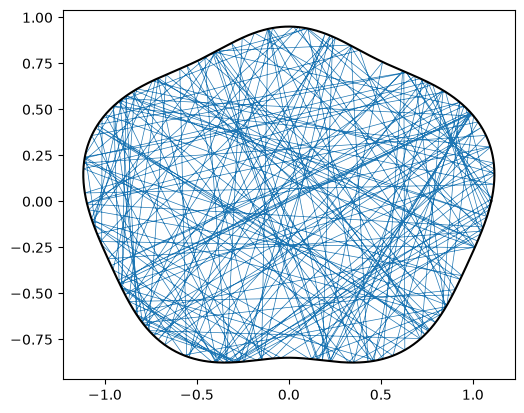

In [25]:
from numba import njit


@njit
def radius(theta, parameters):
    a, b = parameters
    return 1.0 + a * np.cos(2.0 * theta) + b * np.sin(5.0 * theta)


@njit
def dradius(theta, parameters):
    a, b = parameters
    return -2.0 * a * np.sin(2.0 * theta) + 5.0 * b * np.cos(5.0 * theta)


@njit
def ddradius(theta, parameters):
    a, b = parameters
    return -4.0 * a * np.cos(2.0 * theta) - 25.0 * b * np.sin(5.0 * theta)


bl = Billiard.from_polar(radius, dradius, ddradius=ddradius, parameters=[0.1, 0.05], solver="md")
print(bl.info["solver"], bl.perimeter())
plot_billiard(bl, [1.0, 1.0], total_time=200)

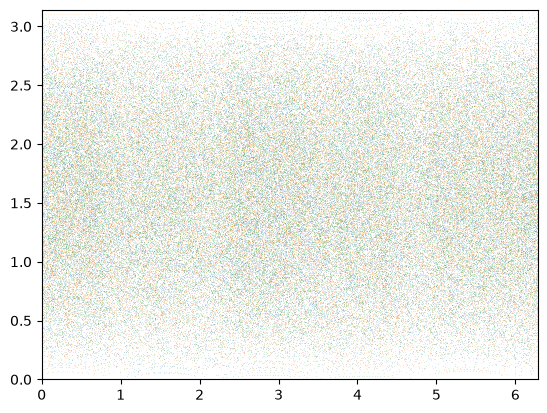

In [26]:
plot_phase_space(bl, [[1.0, 1.0], [1.0, 0.05], [2.0, 1.2]], (0, 2 * np.pi), (0, np.pi), 50_000)

On a convex boundary, `max_radius` gives the much faster `"circle"` solver.

In [27]:
@njit
def max_radius(parameters):
    return 1.0 + abs(parameters[0]) + abs(parameters[1])


md = Billiard.from_polar(radius, dradius, ddradius=ddradius, max_radius=max_radius, parameters=[0.02, 0.01], solver="md")
circle = Billiard.from_polar(radius, dradius, ddradius=ddradius, max_radius=max_radius, parameters=[0.02, 0.01], solver="circle")

%timeit md.trajectory([1.0, 1.0], 10_000)
%timeit circle.trajectory([1.0, 1.0], 10_000)

70.9 ms ± 311 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


3.48 ms ± 22.2 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


A wrong derivative, or `"circle"` on a boundary that is not convex, raises an error.

ddradius is not the derivative of dradius
solver='circle' requires a convex boundary. On a boundary that is not convex, use solver='md'. The boundary is drawn in the figure 'Invalid billiard boundary': notebooks display it, and a script needs plt.show().


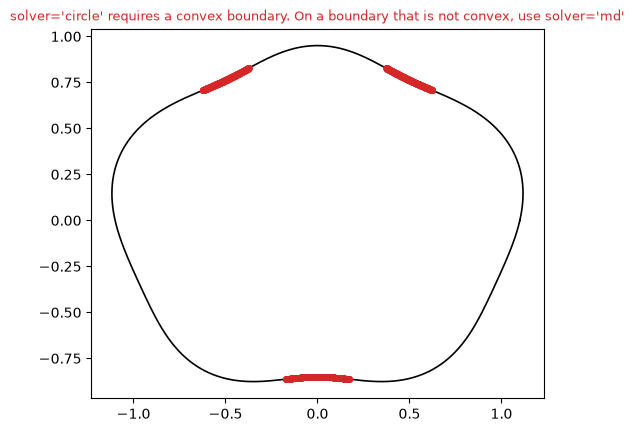

In [28]:
for kwargs in (dict(ddradius=dradius, solver="md"), dict(max_radius=max_radius, solver="circle")):
    try:
        Billiard.from_polar(radius, dradius, parameters=[0.1, 0.05], **kwargs)
    except ValueError as error:
        print(error)

## From lines and arcs

The direction of the pieces matters: the outer boundary runs counterclockwise, and a hole clockwise (a negative `span`). `("arc", center_x, center_y, radius, first_angle, span)`.

exact 8.141592653589793 None


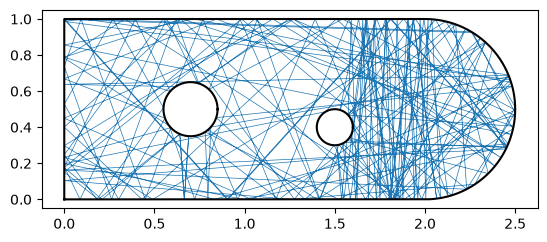

In [29]:
bl = Billiard.from_pieces([
    ("line", 0.0, 0.0, 2.0, 0.0),
    ("arc", 2.0, 0.5, 0.5, -np.pi / 2, np.pi),
    ("line", 2.0, 1.0, 0.0, 1.0),
    ("line", 0.0, 1.0, 0.0, 0.0),
    ("arc", 0.7, 0.5, 0.15, 0.0, -2 * np.pi),
    ("arc", 1.5, 0.4, 0.1, 0.0, -2 * np.pi),
], solver="exact")
print(bl.info["solver"], bl.perimeter(), bl.info["period"])
plot_billiard(bl, [0.5, 1.0], total_time=200)

A boundary that depends on parameters is a function that returns a table.

4.570796326794897 9.141592653589793


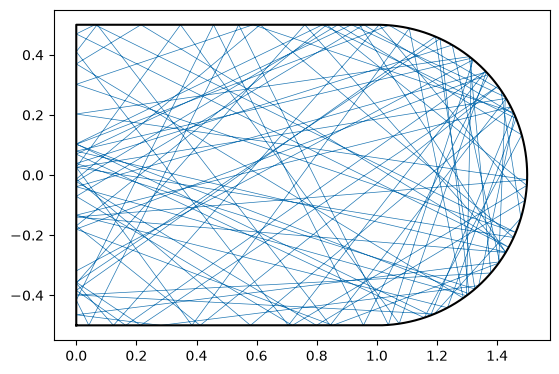

In [30]:
from pynamicalsys.discrete_time.billiards import new_pieces, set_arc, set_line


@njit
def half_stadium(parameters):
    r, l = parameters
    table = new_pieces(4)
    set_line(table, 0, 0.0, -r, l, -r)
    set_arc(table, 1, l, 0.0, r, -np.pi / 2, np.pi)
    set_line(table, 2, l, r, 0.0, r)
    set_line(table, 3, 0.0, r, 0.0, -r)
    return table


bl = Billiard.from_pieces(half_stadium, parameters=[0.5, 1.0], solver="exact")
plot_billiard(bl, [0.3, 1.0], total_time=100)
print(bl.perimeter(), bl.perimeter([1.0, 2.0]))


## Invalid boundaries

A boundary that is not valid raises an error and is drawn, with the problem in red. Here, the boundary is not closed.

the pieces must be connected: each part of the boundary must end where it starts, but piece 2 ends at (0, 1) and piece 0 starts at (0, 0). The boundary is drawn in the figure 'Invalid billiard boundary': notebooks display it, and a script needs plt.show().


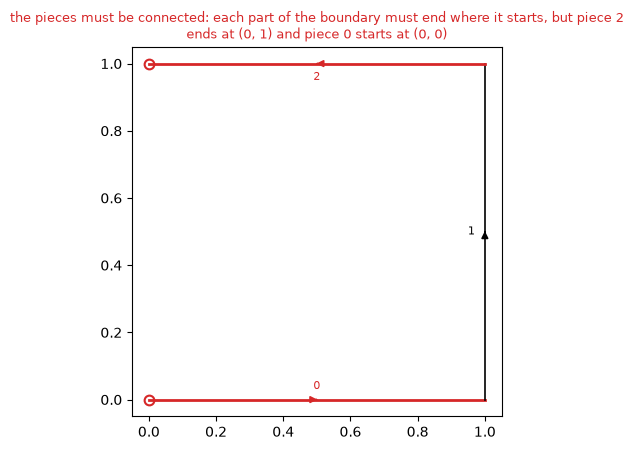

In [31]:
try:
    Billiard.from_pieces([
        ("line", 0.0, 0.0, 1.0, 0.0),
        ("line", 1.0, 0.0, 1.0, 1.0),
        ("line", 1.0, 1.0, 0.0, 1.0),
    ], solver="exact")
except ValueError as error:
    print(error)

Here, the disk intersects a wall.

pieces 2 and 4 cross or touch at (0.326795, 1). The boundary is drawn in the figure 'Invalid billiard boundary': notebooks display it, and a script needs plt.show().


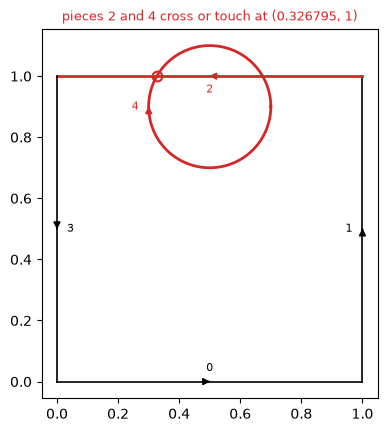

In [32]:
try:
    Billiard.from_pieces([
        ("line", 0.0, 0.0, 1.0, 0.0),
        ("line", 1.0, 0.0, 1.0, 1.0),
        ("line", 1.0, 1.0, 0.0, 1.0),
        ("line", 0.0, 1.0, 0.0, 0.0),
        ("arc", 0.5, 0.9, 0.2, 0.0, -2 * np.pi),
    ], solver="exact")
except ValueError as error:
    print(error)

# Escape through holes

A hole in the boundary is an interval of the position, for any value of the other coordinate: `hole_size=[h, np.inf]`.

In [33]:
bl = Billiard("oval", parameters=[0.08, 3], solver="circle")
bl.escape_analysis([2.0, 1.0], 10_000, exits=[0.2, 0.0], hole_size=[0.2, np.inf])

(0, 7)

A hole at the angle 0 also covers the angles just below $2\pi$.

In [34]:
bl.escape_analysis([2.0, 1.0], 10_000, exits=[0.0, 0.0], hole_size=[0.2, np.inf])

(0, 15)

Holes of different sizes.

In [35]:
centers = [[0.2, 0.0], [4.05, 0.0]]
sizes = [[0.1, np.inf], [0.3, np.inf]]
bl.escape_analysis([2.0, 1.0], 10_000, exits=centers, hole_size=sizes)

(1, 8)

## Survival probability

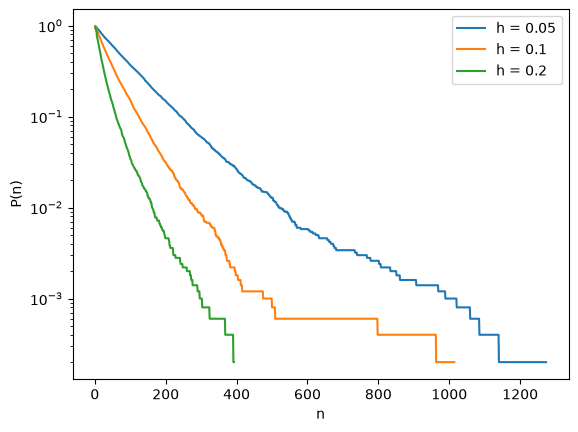

In [36]:
rng = np.random.default_rng(13)
ics = np.column_stack((rng.uniform(3.95, 4.15, 5000), rng.uniform(0, np.pi, 5000)))
max_time = 5000
for h in [0.05, 0.1, 0.2]:
    times = [bl.escape_analysis(u, max_time, exits=[4.05, 0.0], hole_size=[h, np.inf])[1] for u in ics]
    n, P = bl.survival_probability(times, max_time)
    plt.plot(n[P > 0], P[P > 0], label=f"h = {h}")
plt.yscale("log")
plt.xlabel("n")
plt.ylabel("P(n)")
plt.legend()

## Escape basins

Two holes, as in Hansen et al. (2018).

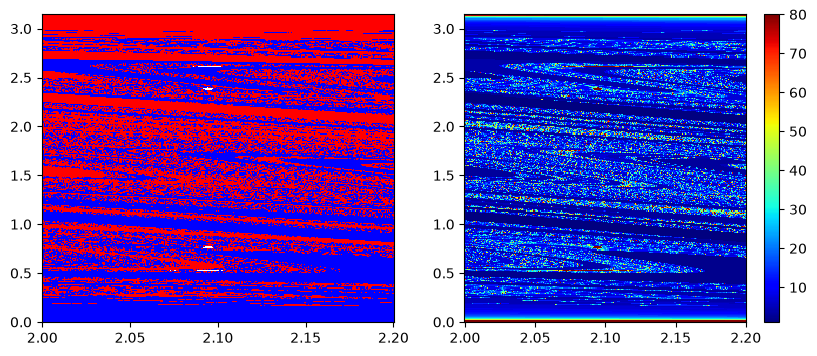

In [37]:
from joblib import Parallel, delayed
from matplotlib.colors import ListedColormap

thetas = np.linspace(2.0, 2.2, 300)
alphas = np.linspace(0.001, np.pi - 0.001, 300)
holes = [[0.2, 0.0], [4.05, 0.0]]
result = Parallel(n_jobs=-1)(
    delayed(bl.escape_analysis)([t, a], 2000, exits=holes, hole_size=[0.2, np.inf])
    for t in thetas for a in alphas
)
basin = np.array(result).reshape(thetas.size, alphas.size, 2)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
cmap = ListedColormap(["white", "red", "blue"])  # No escape, first hole, second hole
ax[0].pcolormesh(thetas, alphas, basin[:, :, 0].T, cmap=cmap, vmin=-1.5, vmax=1.5)
im = ax[1].pcolormesh(thetas, alphas, basin[:, :, 1].T, cmap="jet", vmax=80)
fig.colorbar(im, ax=ax[1])

Arc lengths work the same way. In the stadium, the position wraps at the perimeter; in the Sinai billiard, it does not.

In [38]:
bl = Billiard("stadium", parameters=[1.0, 2.0], solver="exact")
print(bl.info["period"], bl.escape_analysis([3.0, 1.0], 10_000, exits=[0.0, 0.0], hole_size=[0.3, np.inf]))

bl = Billiard("sinai", parameters=[0.2, 0.5, 0.5], solver="exact")
print(bl.info["period"], bl.escape_analysis([0.6, 1.0], 10_000, exits=[0.5, 0.0], hole_size=[0.1, np.inf]))

10.283185307179586 (0, 7)
None (0, 26)
